### Parallel Connection of Cycle Graphs
We construct the cycle graphs $C_m$ and $C_n$ and compute their parallel connection.

In [17]:
import sys
import os

# Setup paths
current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir)
sys.path.insert(0, parent_dir)

from sage.all import *
from custom_matroid_functions import *


Cycle graph C_5:


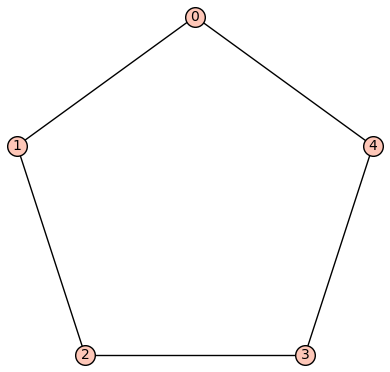


Cycle graph C_5:


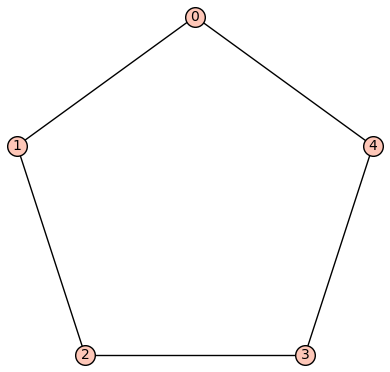


Parallel connection of C_5 and C_5 (with edge (0,0)-(0,1) identified):


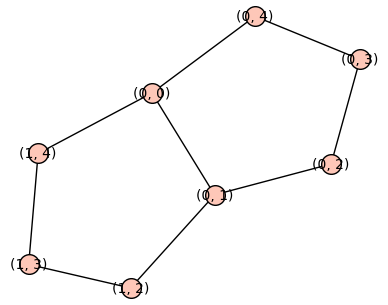


Cycle Matroid of the parallel connection: Graphic matroid of rank 7 on 9 elements


In [18]:
def parallel_connection_of_cycles(m, n):
    """
    Creates the parallel connection of two cycle graphs C_m and C_n.
    The returned graph has m + n - 2 vertices and m + n - 1 edges.
    """
    if m < 3 or n < 3:
        raise ValueError("m and n must be at least 3 for cycle graphs.")
        
    G1 = graphs.CycleGraph(m)
    G2 = graphs.CycleGraph(n)
    
    # Create disjoint union of graphs
    # Vertices of G1 will be labeled (0, v) and of G2 will be labeled (1, v)
    G = G1.disjoint_union(G2)
    
    # In CycleGraph(k), (0, 1) is always an edge.
    # Therefore, ((0, 0), (0, 1)) is an edge in G corresponding to G1.
    # And ((1, 0), (1, 1)) is an edge in G corresponding to G2.
    # We identify (0,0) with (1,0) and (0,1) with (1,1).
    G.merge_vertices([(0, 0), (1, 0)])
    G.merge_vertices([(0, 1), (1, 1)])
    
    # Remove the parallel edge that is formed by merging
    G.allow_multiple_edges(False) 
    
    return G, G1, G2

m = 5
n = 5
G, G1, G2 = parallel_connection_of_cycles(m, n)

# Show the graphs
print(f"\nCycle graph C_{m}:")
_ = G1.show()

print(f"\nCycle graph C_{n}:")
_ = G2.show()

print(f"\nParallel connection of C_{m} and C_{n} (with edge (0,0)-(0,1) identified):")
_ = G.show()

M = Matroid(G)
print(f"\nCycle Matroid of the parallel connection: {M}")

In [19]:
P.<x> = LaurentPolynomialRing(ZZ)

def chow_poly_fn(M):
    return P(chow_polynomial(M))

def kl_rev_fn(M):
    p = kl_poly(M)
    t = p.parent().gen()
    rk = M.rank()
    return P(p.subs({t: x**-1}) * x**rk)

def get_matroid_key(M):
    rank = M.rank()
    size = len(M.groundset())
    try:
        can = M.canonical_form()
        return (rank, size, str(can))
    except AttributeError:
        bases = tuple(sorted(tuple(sorted(b)) for b in M.bases()))
        return (rank, size, str(bases))

def convolution_inverse(f):
    cache_inv = {}
    
    def f_inv(M):
        m_key = get_matroid_key(M)
        if m_key in cache_inv:
            return cache_inv[m_key]
        
        if M.rank() == 0 and M.size() == 0:
            res = 1 / f(M)
            cache_inv[m_key] = res
            return res
        
        # f_inv(M) = - (1/f(empty)) * sum_{empty != F <= E} f(M|F) f_inv(M/F)
        empty_matroid = matroids.Uniform(0, 0)
        f0 = f(empty_matroid)
        
        L = M.lattice_of_flats()
        E = M.groundset()
        
        total = P(0)
        for F in L:
            if len(F) == 0: continue
            restriction = M.delete(list(set(E) - set(F)))
            contraction = M.contract(list(F))
            total += f(restriction) * f_inv(contraction)
            
        res = -total / f0
        cache_inv[m_key] = res
        return res
    
    return f_inv

chow = chow_polynomial
chibar = reduced_characteristic_polynomial
char_poly = characteristic_polynomial
kl_poly = lambda M: M.lattice_of_flats().kazhdan_lusztig_polynomial()(x)
grev = lambda M: P(x**M.rank())
mu_rev = lambda M: P(x**M.rank() * char_poly(M)(0))
mu = lambda M: P(char_poly(M)(0))
F_fn = convolve(chow_poly_fn, kl_rev_fn)
G_fn = convolve(kl_rev_fn, chow_poly_fn)
bbasepoly = convolve(mu_rev, F_fn)
Z_poly = convolve(grev, kl_poly)
q_poly = invkl
Y_poly = convolution_inverse(Z_poly)

F_inv_fn = convolution_inverse(F_fn)
G_inv_fn = convolution_inverse(G_fn)

G_inv_star_F = convolve(G_inv_fn, F_fn)
F_inv_star_G = convolve(F_inv_fn, G_fn)

F_inv_grev = convolve(F_inv_fn, grev)
G_inv_frev = convolve(G_inv_fn, kl_rev_fn)

In [20]:
M = Matroid(G)
e = ((0, 0), (0, 1))
mdele = M.delete(e)
M.groundset()

frozenset({((0, 0), (0, 1)),
           ((0, 0), (0, 4)),
           ((0, 0), (1, 4)),
           ((0, 1), (0, 2)),
           ((0, 1), (1, 2)),
           ((0, 2), (0, 3)),
           ((0, 3), (0, 4)),
           ((1, 2), (1, 3)),
           ((1, 3), (1, 4))})

In [21]:
F_ogM = F_fn(M)
F_delM = F_fn(mdele)
print(F_ogM)
print(F_delM)

1 + 387*x + 7481*x^2 + 28289*x^3 + 28289*x^4 + 7481*x^5 + 387*x^6 + x^7
1 + 267*x + 5153*x^2 + 19573*x^3 + 19573*x^4 + 5153*x^5 + 267*x^6 + x^7


In [22]:
F_ogM - F_delM

120*x + 2328*x^2 + 8716*x^3 + 8716*x^4 + 2328*x^5 + 120*x^6

In [23]:
H1, H2 = graphs.CycleGraph(m-1), graphs.CycleGraph(n-1)
subF1, subF2 = F_fn(matroids.Uniform(m - 1, m - 1)), F_fn(Matroid(H2))


In [24]:
x * subF1 * subF2

x + 28*x^2 + 241*x^3 + 640*x^4 + 640*x^5 + 241*x^6 + 28*x^7 + x^8